In [7]:
import sqlite3
import pandas as pd
import os
import matplotlib.pyplot as plt

path = ""
for root, dirs, files in os.walk("../input"):
    if "olist_orders_dataset.csv" in files:
        path = root
        break

print(path)

conn = sqlite3.connect("olist.db")

pd.read_csv(os.path.join(path, "olist_orders_dataset.csv")).to_sql("olist_orders", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv")).to_sql("olist_order_items", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_products_dataset.csv")).to_sql("olist_products", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv")).to_sql("olist_order_reviews", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv")).to_sql("olist_sellers", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_customers_dataset.csv")).to_sql("olist_customers", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "product_category_name_translation.csv")).to_sql("product_category_name_translation", conn, if_exists="replace", index=False)
pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv")).to_sql("olist_order_payments", conn, if_exists="replace", index=False)

../input/datasets/olistbr/brazilian-ecommerce


103886

In [3]:
sql_1 = "SELECT name FROM sqlite_master WHERE type='table';"
print(pd.read_sql(sql_1, conn))

                                name
0                       olist_orders
1                  olist_order_items
2                     olist_products
3                olist_order_reviews
4                      olist_sellers
5                    olist_customers
6  product_category_name_translation


In [22]:
# Category Name according to High Sales Amount

sql_2="""SELECT 
    t.product_category_name_english AS category,
    SUM(i.price) AS total_revenue
FROM product_category_name_translation t
JOIN olist_products p ON t.product_category_name = p.product_category_name
JOIN olist_order_items i ON p.product_id = i.product_id
GROUP BY t.product_category_name_english
ORDER BY total_revenue DESC
LIMIT 1;"""

print(df.read_sql(sql_2, conn))

In [8]:
# category name according to order_items count

sql_3 = """SELECT ok 
    t.product_category_name_english,
    COUNT(i.order_id) AS total_orders
FROM product_category_name_translation t
JOIN olist_products p ON t.product_category_name = p.product_category_name
JOIN olist_order_items i ON p.product_id = i.product_id"""
print(pd.read_sql(sql_3, conn))

  product_category_name_english  total_orders
0                 health_beauty        111023


In [9]:
sql_4 = """SELECT 
    t.product_category_name_english AS category,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(i.price), 2) AS total_revenue
FROM olist_orders o
JOIN olist_order_items i ON o.order_id = i.order_id
JOIN olist_products p ON i.product_id = p.product_id
JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY t.product_category_name_english
ORDER BY total_revenue DESC;"""
print(pd.read_sql(sql_4, conn))

                     category  total_orders  total_revenue
0               health_beauty          8647     1233131.72
1               watches_gifts          5495     1166176.98
2              bed_bath_table          9272     1023434.76
3              sports_leisure          7530      954852.55
4       computers_accessories          6530      888724.61
..                        ...           ...            ...
66                    flowers            29        1110.04
67             home_comfort_2            24         760.27
68          cds_dvds_musicals            12         730.00
69  fashion_childrens_clothes             7         519.95
70      security_and_services             2         283.29

[71 rows x 3 columns]


In [10]:
sql_5 = """SELECT 
    c.customer_city AS city,
    ROUND(SUM(i.price), 2) AS total_revenue
FROM olist_customers c
JOIN olist_orders o ON c.customer_id = o.customer_id
JOIN olist_order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_city
ORDER BY total_revenue DESC
LIMIT 10;"""
print(pd.read_sql(sql_5,conn))

             city  total_revenue
0       sao paulo     1859556.83
1  rio de janeiro      955573.97
2  belo horizonte      346039.04
3        brasilia      295814.72
4        curitiba      205999.33
5        campinas      184657.87
6    porto alegre      182319.55
7        salvador      173273.05
8       guarulhos      139008.19
9         niteroi      115890.26


In [23]:
# Temporal Trend Analysis

query = """SELECT 
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(i.price), 2) AS total_revenue
FROM olist_orders o
JOIN olist_order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY order_month
ORDER BY order_month;"""

print(pd.read_sql(query, conn))

   order_month  total_orders  total_revenue
0      2016-09             1         134.97
1      2016-10           265       40325.11
2      2016-12             1          10.90
3      2017-01           750      111798.36
4      2017-02          1653      234223.40
5      2017-03          2546      359198.85
6      2017-04          2303      340669.68
7      2017-05          3546      489338.25
8      2017-06          3135      421923.37
9      2017-07          3872      481604.52
10     2017-08          4193      554699.70
11     2017-09          4150      607399.67
12     2017-10          4478      648247.65
13     2017-11          7289      987765.37
14     2017-12          5513      726033.19
15     2018-01          7069      924645.00
16     2018-02          6555      826437.13
17     2018-03          7003      953356.25
18     2018-04          6798      973534.09
19     2018-05          6749      977544.69
20     2018-06          6099      856077.86
21     2018-07          6159    

In [24]:

# Average Delivery Days and Total Orders by Customer State
sql_7 = """
SELECT 
    c.customer_state AS state,
    ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 1) AS avg_delivery_days,
    COUNT(o.order_id) AS total_orders
FROM olist_orders o
JOIN olist_customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY avg_delivery_days ASC;
"""

df_7 = pd.read_sql(sql_7, conn)
print(df_7)

   state  avg_delivery_days  total_orders
0     SP                8.8         40494
1     MG               12.0         11354
2     PR               12.0          4923
3     DF               13.0          2080
4     SC               15.0          3546
5     RJ               15.3         12350
6     RS               15.3          5344
7     GO               15.6          1957
8     MS               15.6           701
9     ES               15.8          1995
10    TO               17.7           274
11    MT               18.1           886
12    PE               18.4          1593
13    BA               19.3          3256
14    RN               19.3           474
15    RO               19.4           243
16    PI               19.5           476
17    PB               20.4           517
18    AC               21.0            80
19    CE               21.3          1279
20    SE               21.5           335
21    MA               21.6           717
22    PA               23.8       

In [6]:
# Customer Payment Behaviour Analysis

sql_8 = """SELECT 
    payment_type,
    COUNT(order_id) AS total_transactions,
    ROUND(SUM(payment_value), 2) AS total_spent,
    ROUND(AVG(payment_value), 2) AS avg_transaction_value
FROM olist_order_payments
GROUP BY payment_type
ORDER BY total_spent DESC;"""

print(pd.read_sql(sql_8, conn))

  payment_type  total_transactions  total_spent  avg_transaction_value
0  credit_card               76795  12542084.19                 163.32
1       boleto               19784   2869361.27                 145.03
2      voucher                5775    379436.87                  65.70
3   debit_card                1529    217989.79                 142.57
4  not_defined                   3         0.00                   0.00


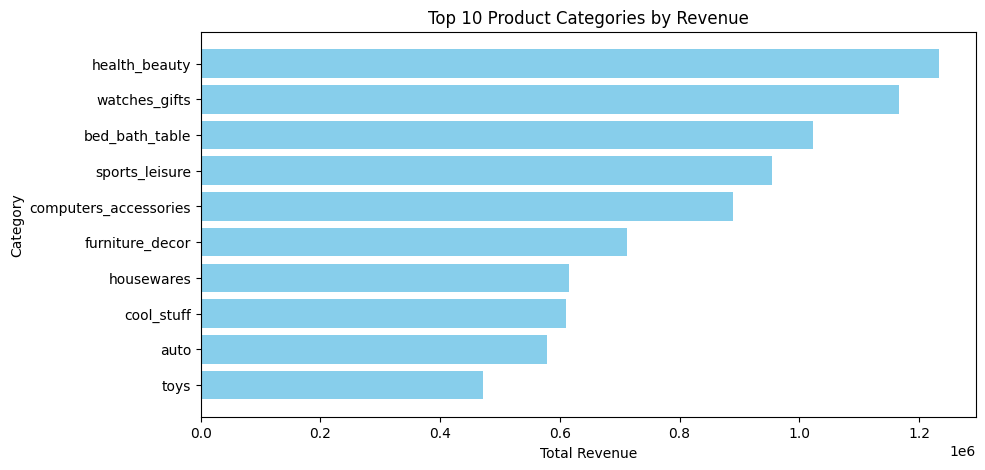

                category  total_revenue
0          health_beauty     1233131.72
1          watches_gifts     1166176.98
2         bed_bath_table     1023434.76
3         sports_leisure      954852.55
4  computers_accessories      888724.61
5        furniture_decor      711927.69
6             housewares      615628.69
7             cool_stuff      610204.10
8                   auto      578966.65
9                   toys      471286.48


In [8]:
# Top 10 Product Categories by Total Revenue 

sql_9 = """
SELECT 
    t.product_category_name_english AS category,
    ROUND(SUM(i.price), 2) AS total_revenue
FROM olist_order_items i
JOIN olist_orders o ON i.order_id = o.order_id
JOIN olist_products p ON i.product_id = p.product_id
JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY total_revenue DESC
LIMIT 10;
"""

df = pd.read_sql(sql_9, conn)

plt.figure(figsize=(10, 5))
plt.barh(df['category'], df['total_revenue'], color='skyblue')
plt.gca().invert_yaxis()  

plt.xlabel('Total Revenue')
plt.ylabel('Category')
plt.title('Top 10 Product Categories by Revenue')
plt.show()

print(pd.read_sql(sql_9, conn))

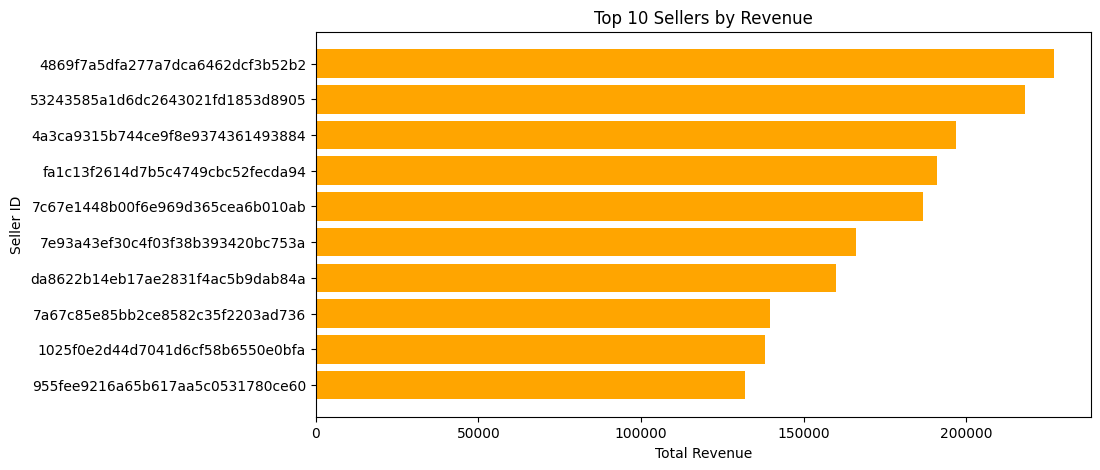

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

query = """
SELECT 
    i.seller_id,
    ROUND(SUM(i.price), 2) AS total_revenue,
    COUNT(i.order_item_id) AS total_items_sold
FROM olist_order_items i
JOIN olist_orders o ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY i.seller_id
ORDER BY total_revenue DESC
LIMIT 10;
"""

df = pd.read_sql(query, conn)

plt.figure(figsize=(10, 5))
plt.barh(df['seller_id'], df['total_revenue'], color='orange')
plt.gca().invert_yaxis()

plt.xlabel('Total Revenue')
plt.ylabel('Seller ID')
plt.title('Top 10 Sellers by Revenue')
plt.show()

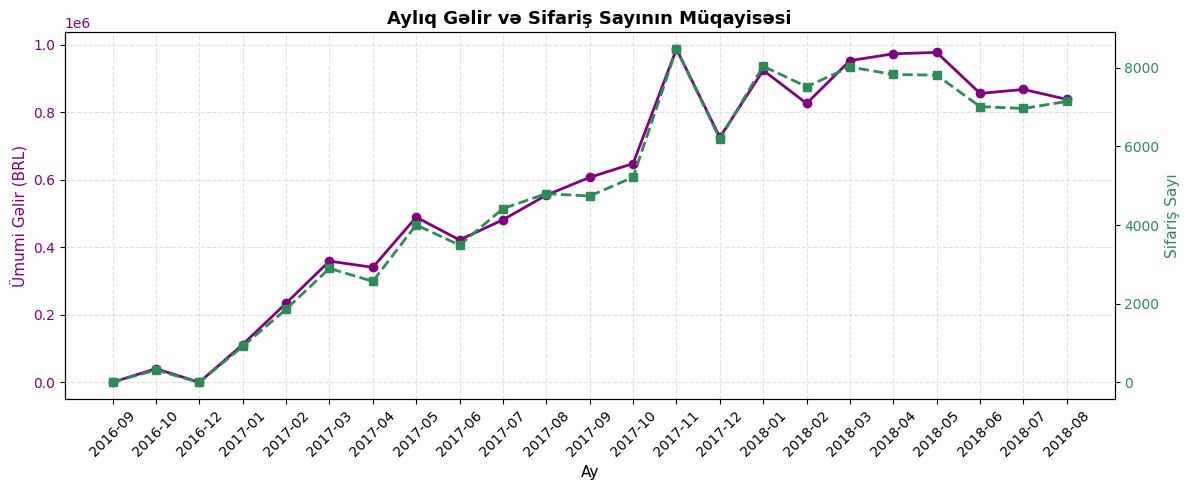

In [10]:
# Monthly Sale Trend

query = """
SELECT 
    strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
    ROUND(SUM(i.price), 2) AS monthly_revenue, count(o.order_id) as order_count
FROM olist_orders o
JOIN olist_order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY order_month
ORDER BY order_month;
"""

df = pd.read_sql(query, conn)

fig, ax1 = plt.subplots(figsize=(12, 5))

# Sol ox: Gəlir (Revenue)
color = 'purple'
ax1.set_xlabel('Ay', fontsize=11)
ax1.set_ylabel('Ümumi Gəlir (BRL)', color=color, fontsize=11)
line1 = ax1.plot(df['order_month'], df['monthly_revenue'], color=color, marker='o', linewidth=2, label='Gəlir')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(len(df['order_month'])))
ax1.set_xticklabels(df['order_month'], rotation=45)

# Sağ ox: Sifariş Sayı (Order Count)
ax2 = ax1.twinx()  
color = 'seagreen'
ax2.set_ylabel('Sifariş Sayı', color=color, fontsize=11)
line2 = ax2.plot(df['order_month'], df['order_count'], color=color, marker='s', linestyle='--', linewidth=2, label='Sifariş Sayı')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Aylıq Gəlir və Sifariş Sayının Müqayisəsi', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()

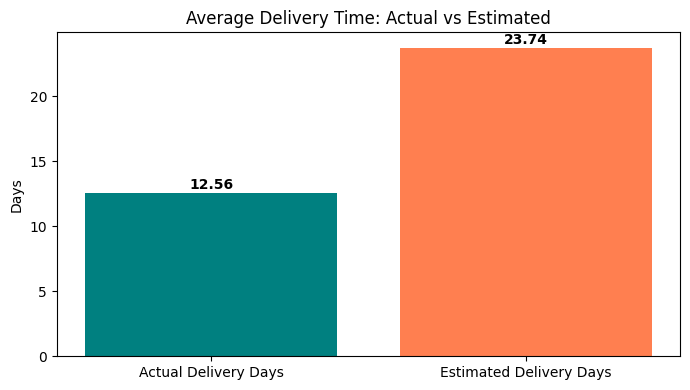

In [15]:
# Delivery Performance Analysis: Estimated vs Actual Delivery Days

query = """
SELECT 
    ROUND(AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)), 2) AS avg_actual_delivery_days,
    ROUND(AVG(julianday(order_estimated_delivery_date) - julianday(order_purchase_timestamp)), 2) AS avg_estimated_delivery_days
FROM olist_orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL;
"""

df = pd.read_sql(query, conn)

metrics = ['Actual Delivery Days', 'Estimated Delivery Days']
values = [df['avg_actual_delivery_days'][0], df['avg_estimated_delivery_days'][0]]

plt.figure(figsize=(7, 4))
plt.bar(metrics, values, color=['teal', 'coral'])
plt.ylabel('Days')
plt.title('Average Delivery Time: Actual vs Estimated')

for i, v in enumerate(values):
    plt.text(i, v + 0.3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


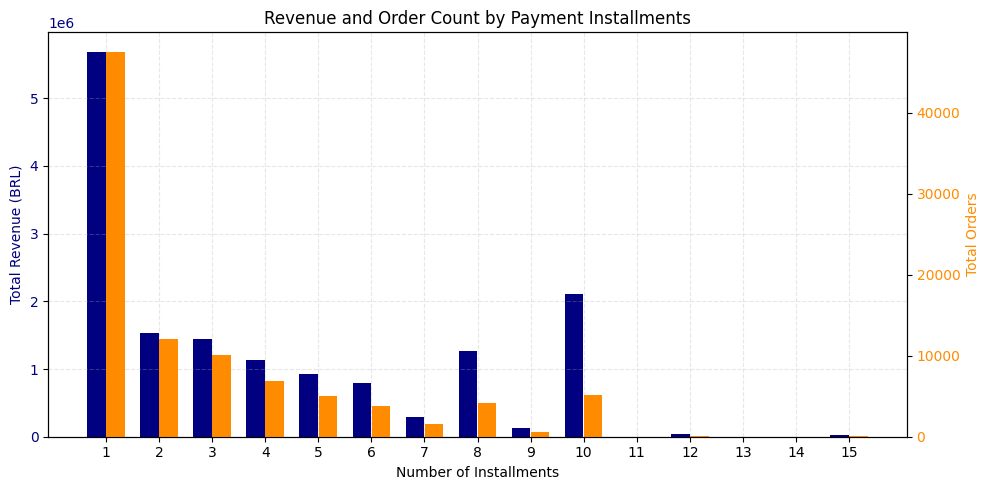

In [11]:
# Payment Installments Analysis: Revenue & Order Volume by Installment Count

query = """
SELECT 
    p.payment_installments,
    ROUND(SUM(p.payment_value), 2) AS total_revenue,
    COUNT(DISTINCT p.order_id) AS total_orders
FROM olist_order_payments p
JOIN olist_orders o ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND p.payment_installments > 0
GROUP BY p.payment_installments
ORDER BY p.payment_installments
LIMIT 15;
"""

df = pd.read_sql(query, conn)

fig, ax1 = plt.subplots(figsize=(10, 5))


color = 'navy'
ax1.set_xlabel('Number of Installments')
ax1.set_ylabel('Total Revenue (BRL)', color=color)
ax1.bar(df['payment_installments'] - 0.18, df['total_revenue'], width=0.35, color=color, label='Revenue')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(df['payment_installments'])
ax1.grid(True, linestyle='--', alpha=0.3)  # Grid yalnız ax1 üçün qoşulur


ax2 = ax1.twinx()
color = 'darkorange'
ax2.set_ylabel('Total Orders', color=color)
ax2.bar(df['payment_installments'] + 0.18, df['total_orders'], width=0.35, color=color, label='Orders')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Revenue and Order Count by Payment Installments')
fig.tight_layout()
plt.show()

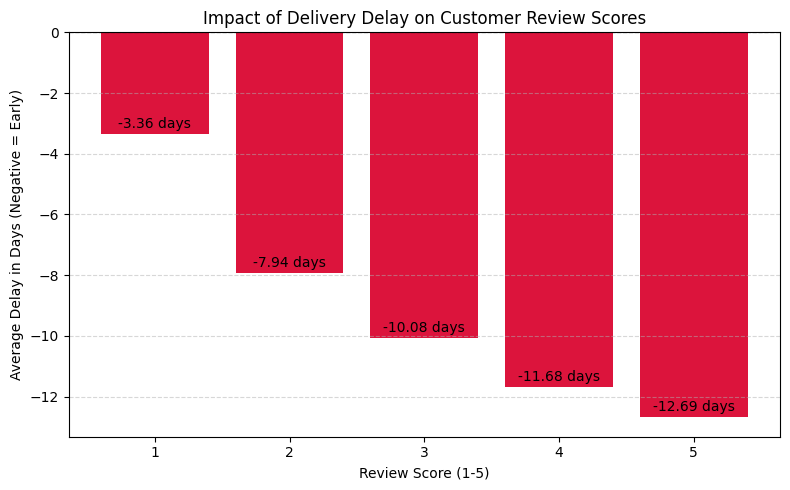

In [18]:
# Customer Review Score vs Delivery Delay Analysis

query = """
SELECT 
    r.review_score,
    ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date)), 2) AS avg_delay_days,
    COUNT(DISTINCT o.order_id) AS total_orders
FROM olist_order_reviews r
JOIN olist_orders o ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY r.review_score
ORDER BY r.review_score;
"""

df = pd.read_sql(query, conn)

plt.figure(figsize=(8, 5))
plt.bar(df['review_score'], df['avg_delay_days'], color='crimson')

plt.xlabel('Review Score (1-5)')
plt.ylabel('Average Delay in Days (Negative = Early)')
plt.title('Impact of Delivery Delay on Customer Review Scores')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, row in df.iterrows():
    plt.text(row['review_score'], row['avg_delay_days'] + 0.2, f"{row['avg_delay_days']} days", ha='center')

plt.tight_layout()
plt.show()

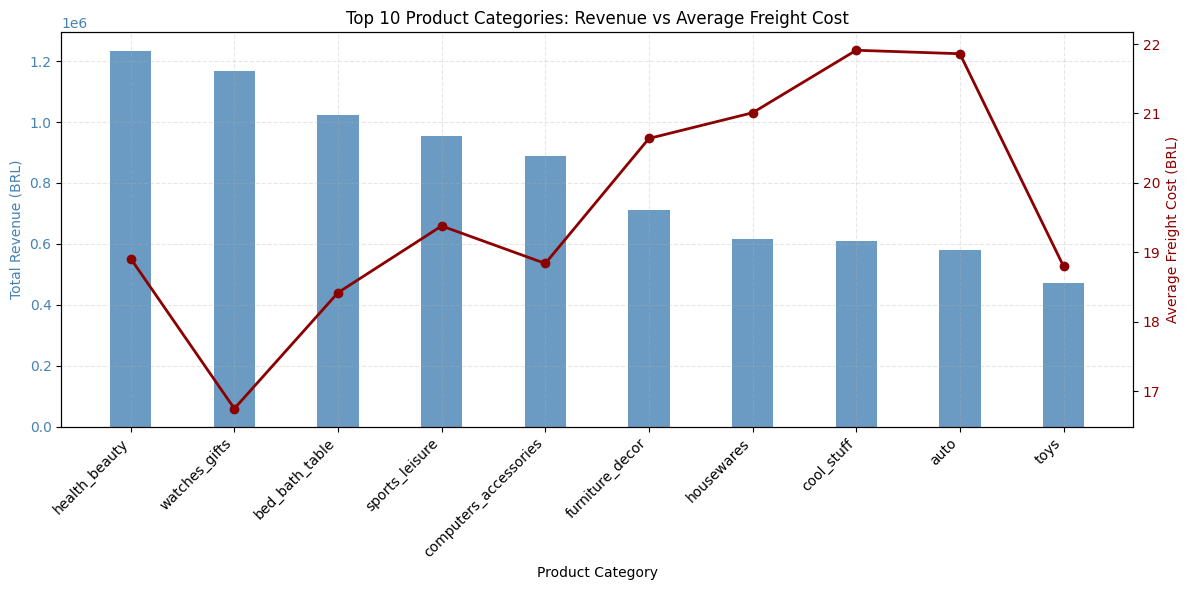

In [20]:
# Product Category Revenue vs Average Freight Cost Analysis

query = """
SELECT 
    t.product_category_name_english AS category,
    ROUND(SUM(i.price), 2) AS total_revenue,
    ROUND(AVG(i.freight_value), 2) AS avg_freight_cost
FROM olist_order_items i
JOIN olist_orders o ON i.order_id = o.order_id
JOIN olist_products p ON i.product_id = p.product_id
JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY total_revenue DESC
LIMIT 10;
"""

df = pd.read_sql(query, conn)

fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'steelblue'
ax1.set_xlabel('Product Category')
ax1.set_ylabel('Total Revenue (BRL)', color=color)
ax1.bar(df['category'], df['total_revenue'], color=color, alpha=0.8, width=0.4, align='center', label='Revenue')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(len(df['category'])))
ax1.set_xticklabels(df['category'], rotation=45, ha='right')

ax2 = ax1.twinx()
color = 'darkred'
ax2.set_ylabel('Average Freight Cost (BRL)', color=color)
ax2.plot(df['category'], df['avg_freight_cost'], color=color, marker='o', linewidth=2, label='Avg Freight')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Top 10 Product Categories: Revenue vs Average Freight Cost')
ax1.grid(True, linestyle='--', alpha=0.3)
fig.tight_layout()
plt.show()